In [22]:
from qiskit.circuit.library import ZGate, XGate, RZGate, RXGate
from qiskit import QiskitError, generate_preset_pass_manager
from qiskit.converters import circuit_to_dag, dag_to_circuit
from utils.circs import remove_idle_qwires
from qiskit.quantum_info import Clifford
from qiskit_aer import AerSimulator
import numpy as np

def is_clifford(gate):
    try:
        Clifford(gate)
        return True
    except QiskitError:
        return False
    
def closest_clifford_angle(angle):
    clifford_angles = np.array([0, np.pi/2, np.pi, 3*np.pi/2])
    min_ind = np.argmin(np.abs(((angle % (2*np.pi))- clifford_angles)))
    return clifford_angles[min_ind]

def clifforize_our_circuit(circuit, angle_function, backend=None):
    layout = circuit.layout.initial_index_layout() if circuit.layout is not None else None
    dag = circuit_to_dag(circuit)
    for node in dag.op_nodes():
        if not is_clifford(node.op) and node.op.name != "measure":
            angle = node.op.params[0]
            new_angle = angle_function(angle)
            if node.op.name == "rz":
                dag.substitute_node(node, RZGate(new_angle))
            elif node.op.name == "rx":
                dag.substitute_node(node, RXGate(new_angle))
            else:
                raise ValueError("Unsupported gate type")
        elif node.op.name == "barrier":
            pass
        # elif node.op.name != "measure":
        #     dag.substitute_node(node, Clifford(node.op))
    clifford_circuit = dag_to_circuit(dag)
    if circuit.layout is not None:
        active_qubits = circuit.num_qubits - len(list(dag.idle_wires()))
        clifford_circuit = remove_idle_qwires(clifford_circuit, relabeling=np.arange(active_qubits)[np.argsort(circuit.layout.initial_index_layout()[:active_qubits])])
        # if backend is not None:
        #     pm = generate_preset_pass_manager(optimization_level=0, backend=backend, initial_layout=layout[:active_qubits])
        # else:
        #     pm = generate_preset_pass_manager(optimization_level=0, initial_layout=layout[:active_qubits])#backend=AerSimulator(method="stabilizer")
        # clifford_circuit = pm.run(clifford_circuit)
    return clifford_circuit

# Device selection

In [23]:
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Simulator settings

In [24]:
from z2chain.gdd import zero_mean
from functools import partial
import numpy as np

L = 5
J = 2
h = 0.8
lamb = 1

x_basis = False

fractional_gates = False

particle_position = 2

final_time = 5
dt = 0.15
steps = 40
desired_error = 1e-2

shots = 75000
confidence = 0.7

odr = True
flip_threshold = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean
# g_func = None

# Ground truth

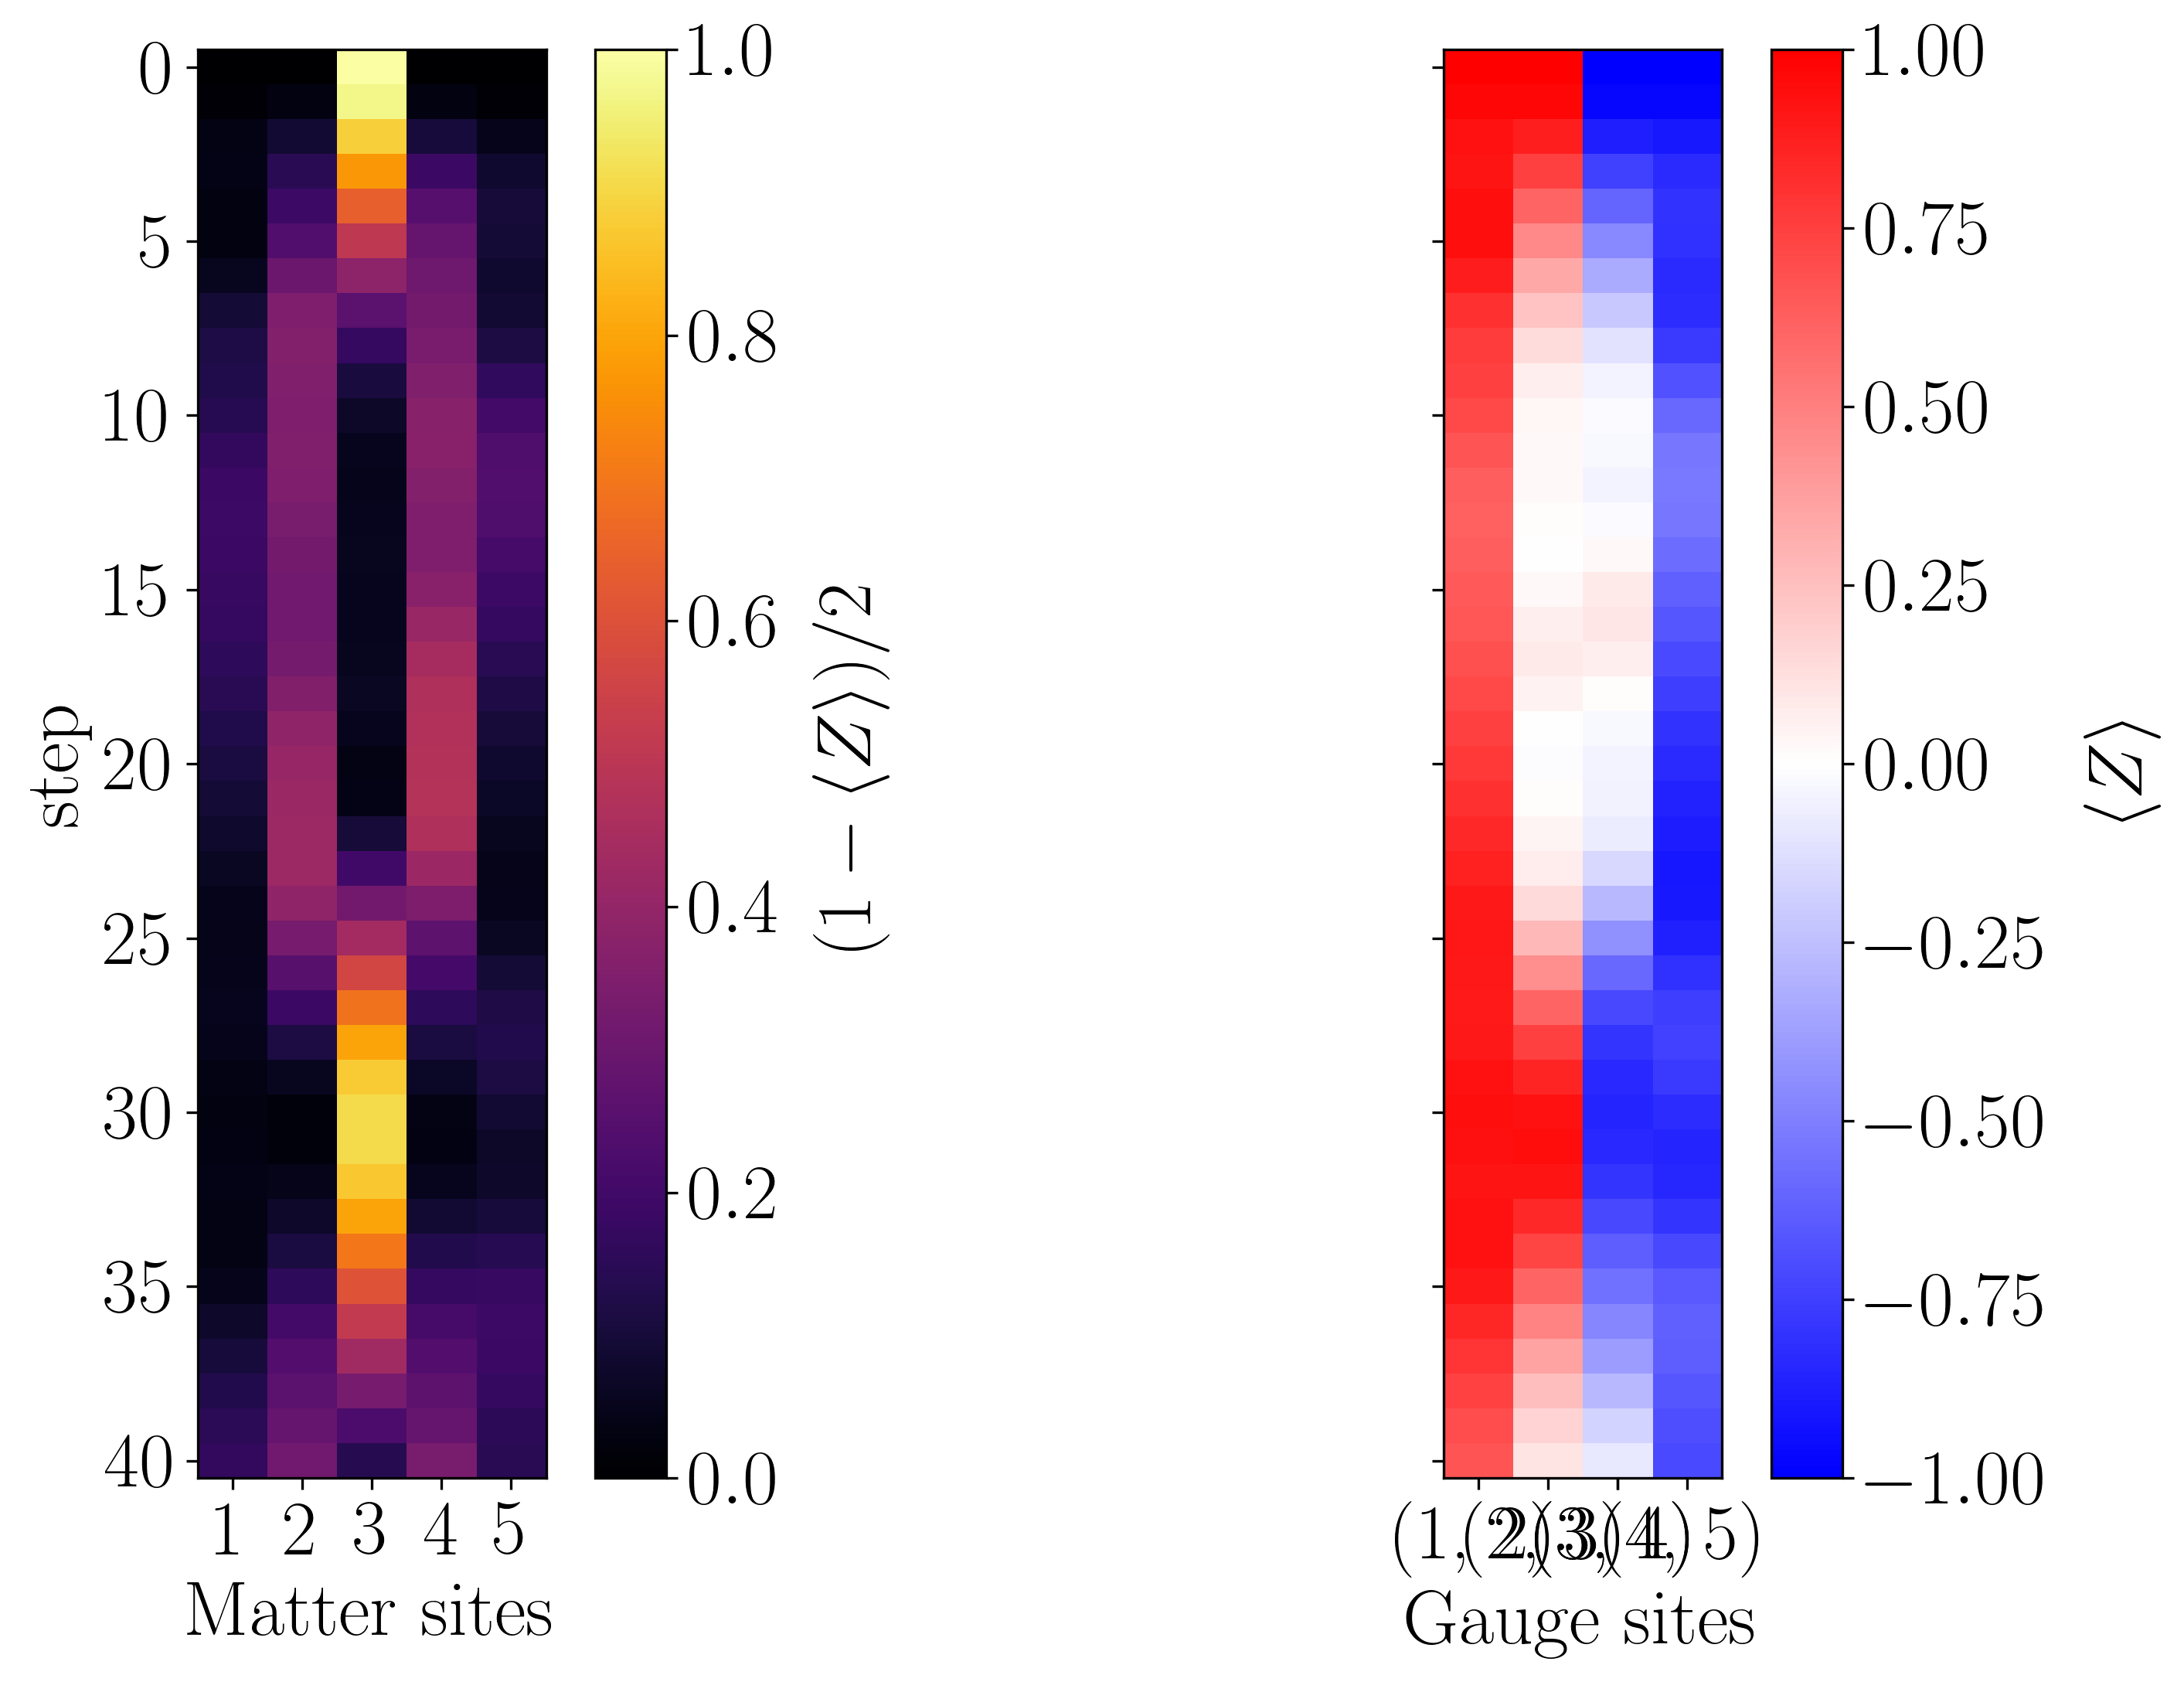

In [25]:
from z2chain.plotting import x_t_separated_plot
import z2chain.exact as exact

exact_observables = exact.singlep_quench_simulation(L, J, h, lamb, particle_position, final_time/steps, steps)

x_t_separated_plot(exact_observables)

# Noisy simulation with Clifford ODR

## Circuit transpilation

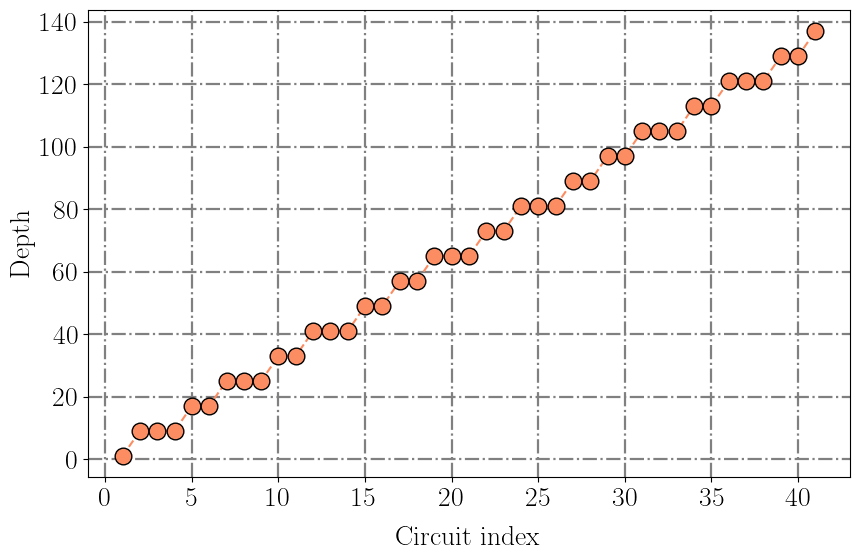

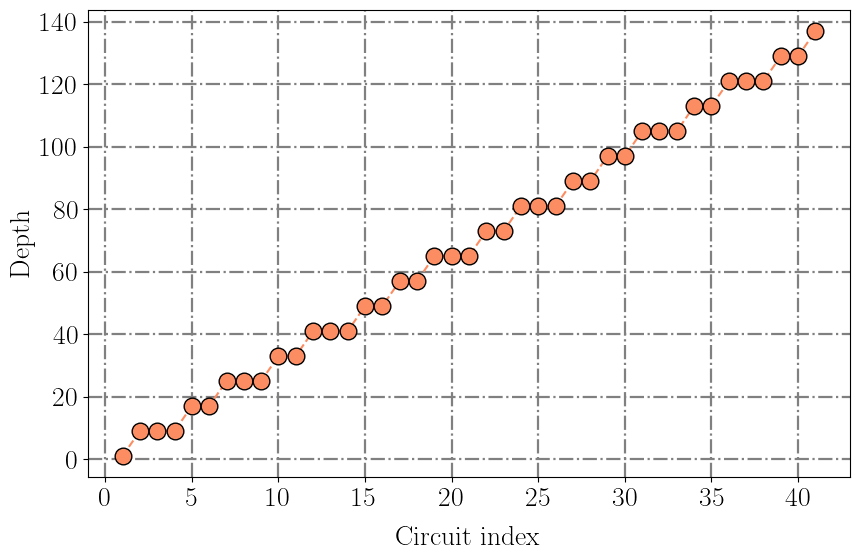

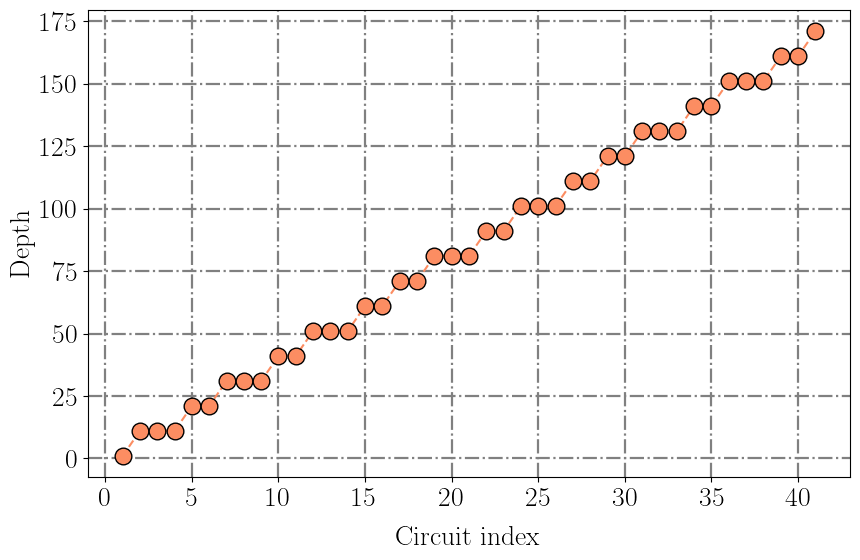

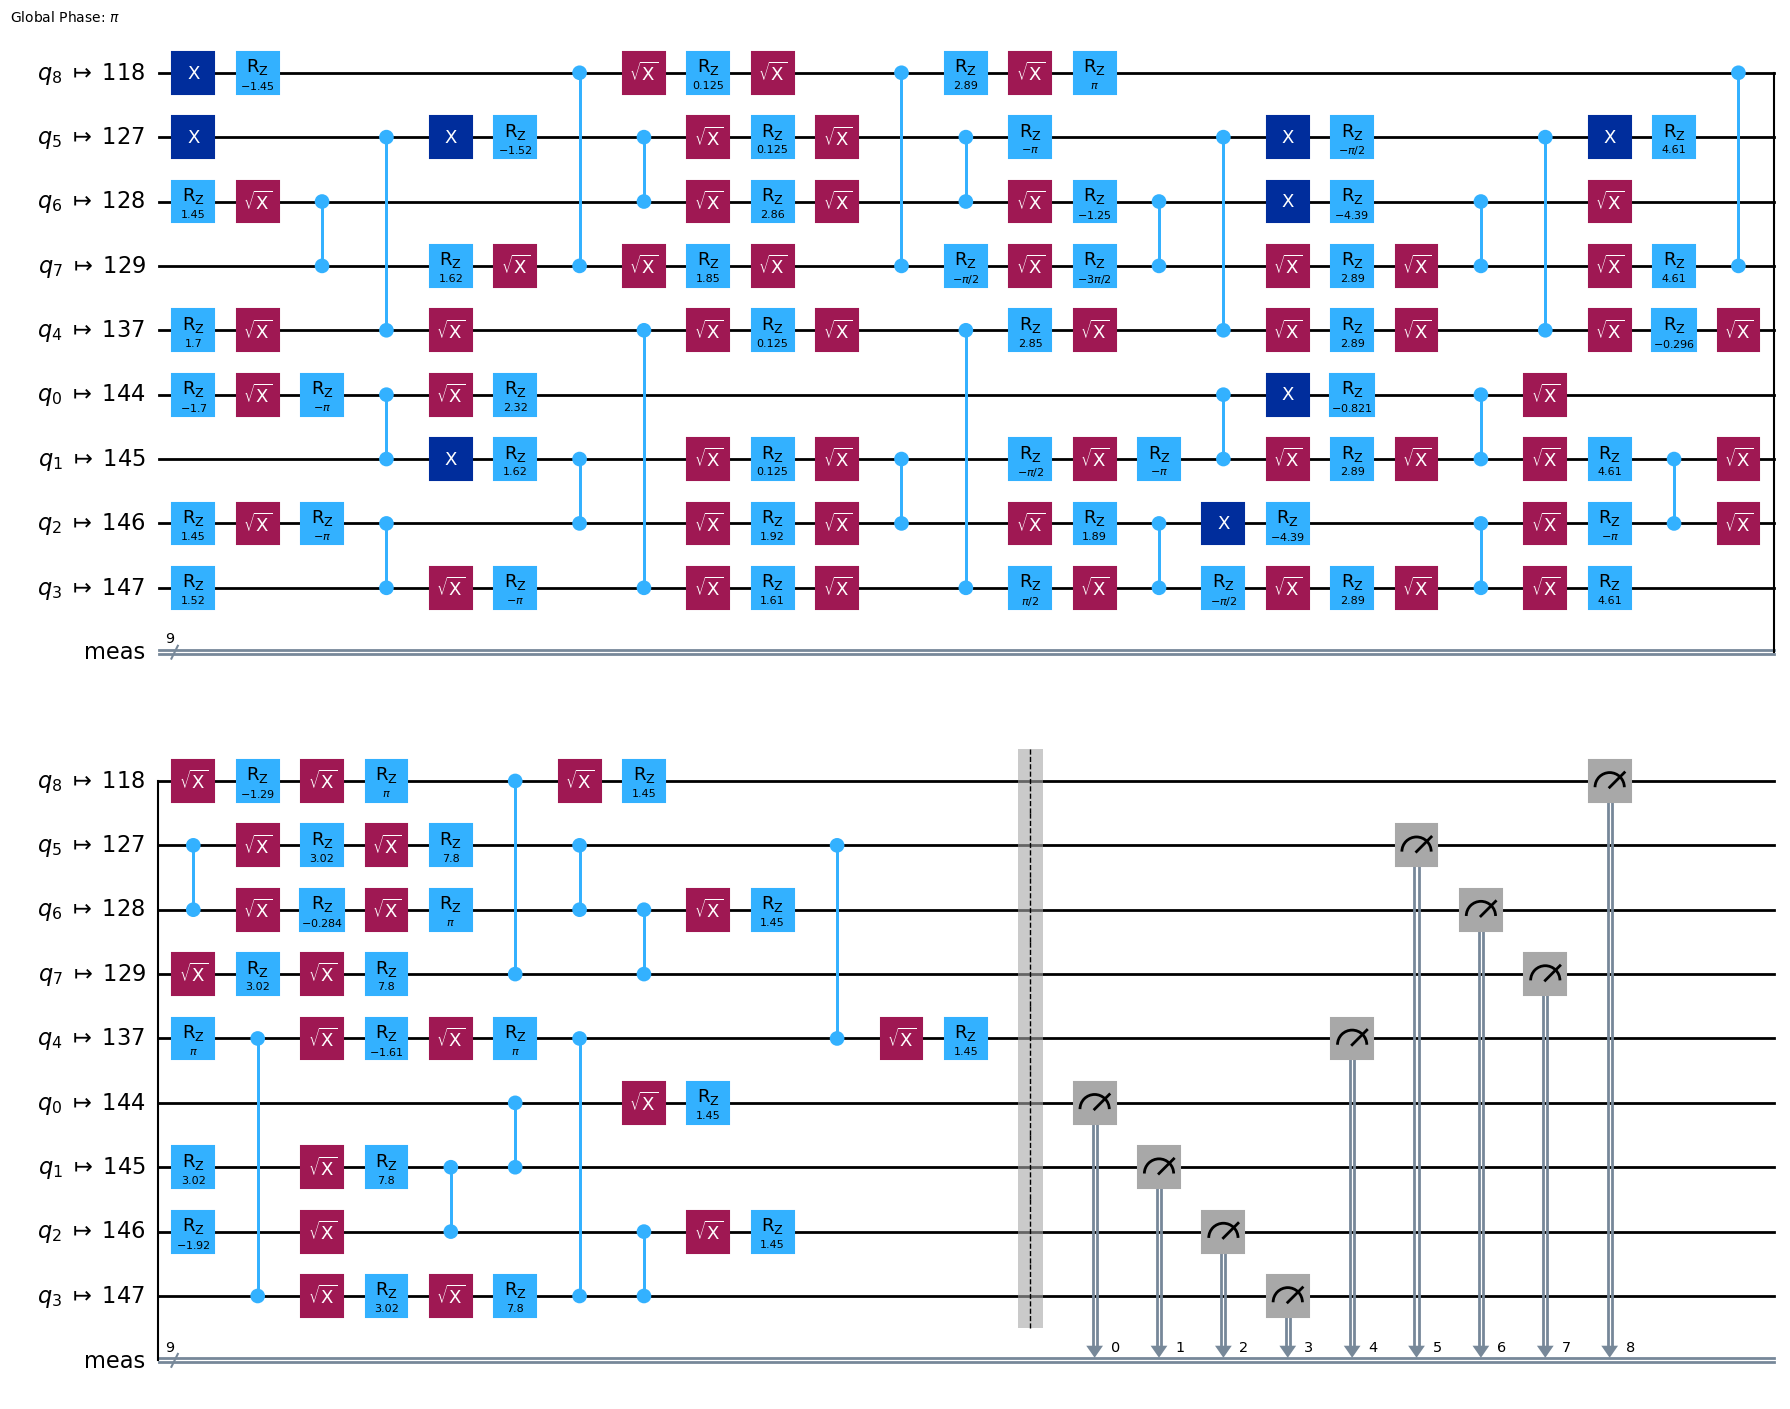

In [ ]:
from z2chain.circs2 import singlep_quench_simulation_and_odr_clifford_circs
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
import numpy as np
import os

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
circs_args = (L, J, h, lamb, particle_position, final_time, dt, steps, backend, optimization_level, g_func, layout, x_basis, False, True)
circuits, odr_circuits, aer_circuits = singlep_quench_simulation_and_odr_clifford_circs(*circs_args)
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

plot_circuit_arr_depth(circuits)
plot_circuit_arr_depth(odr_circuits)
plot_circuit_arr_depth(aer_circuits)
circuits[1].draw(output="mpl", idle_wires=False)

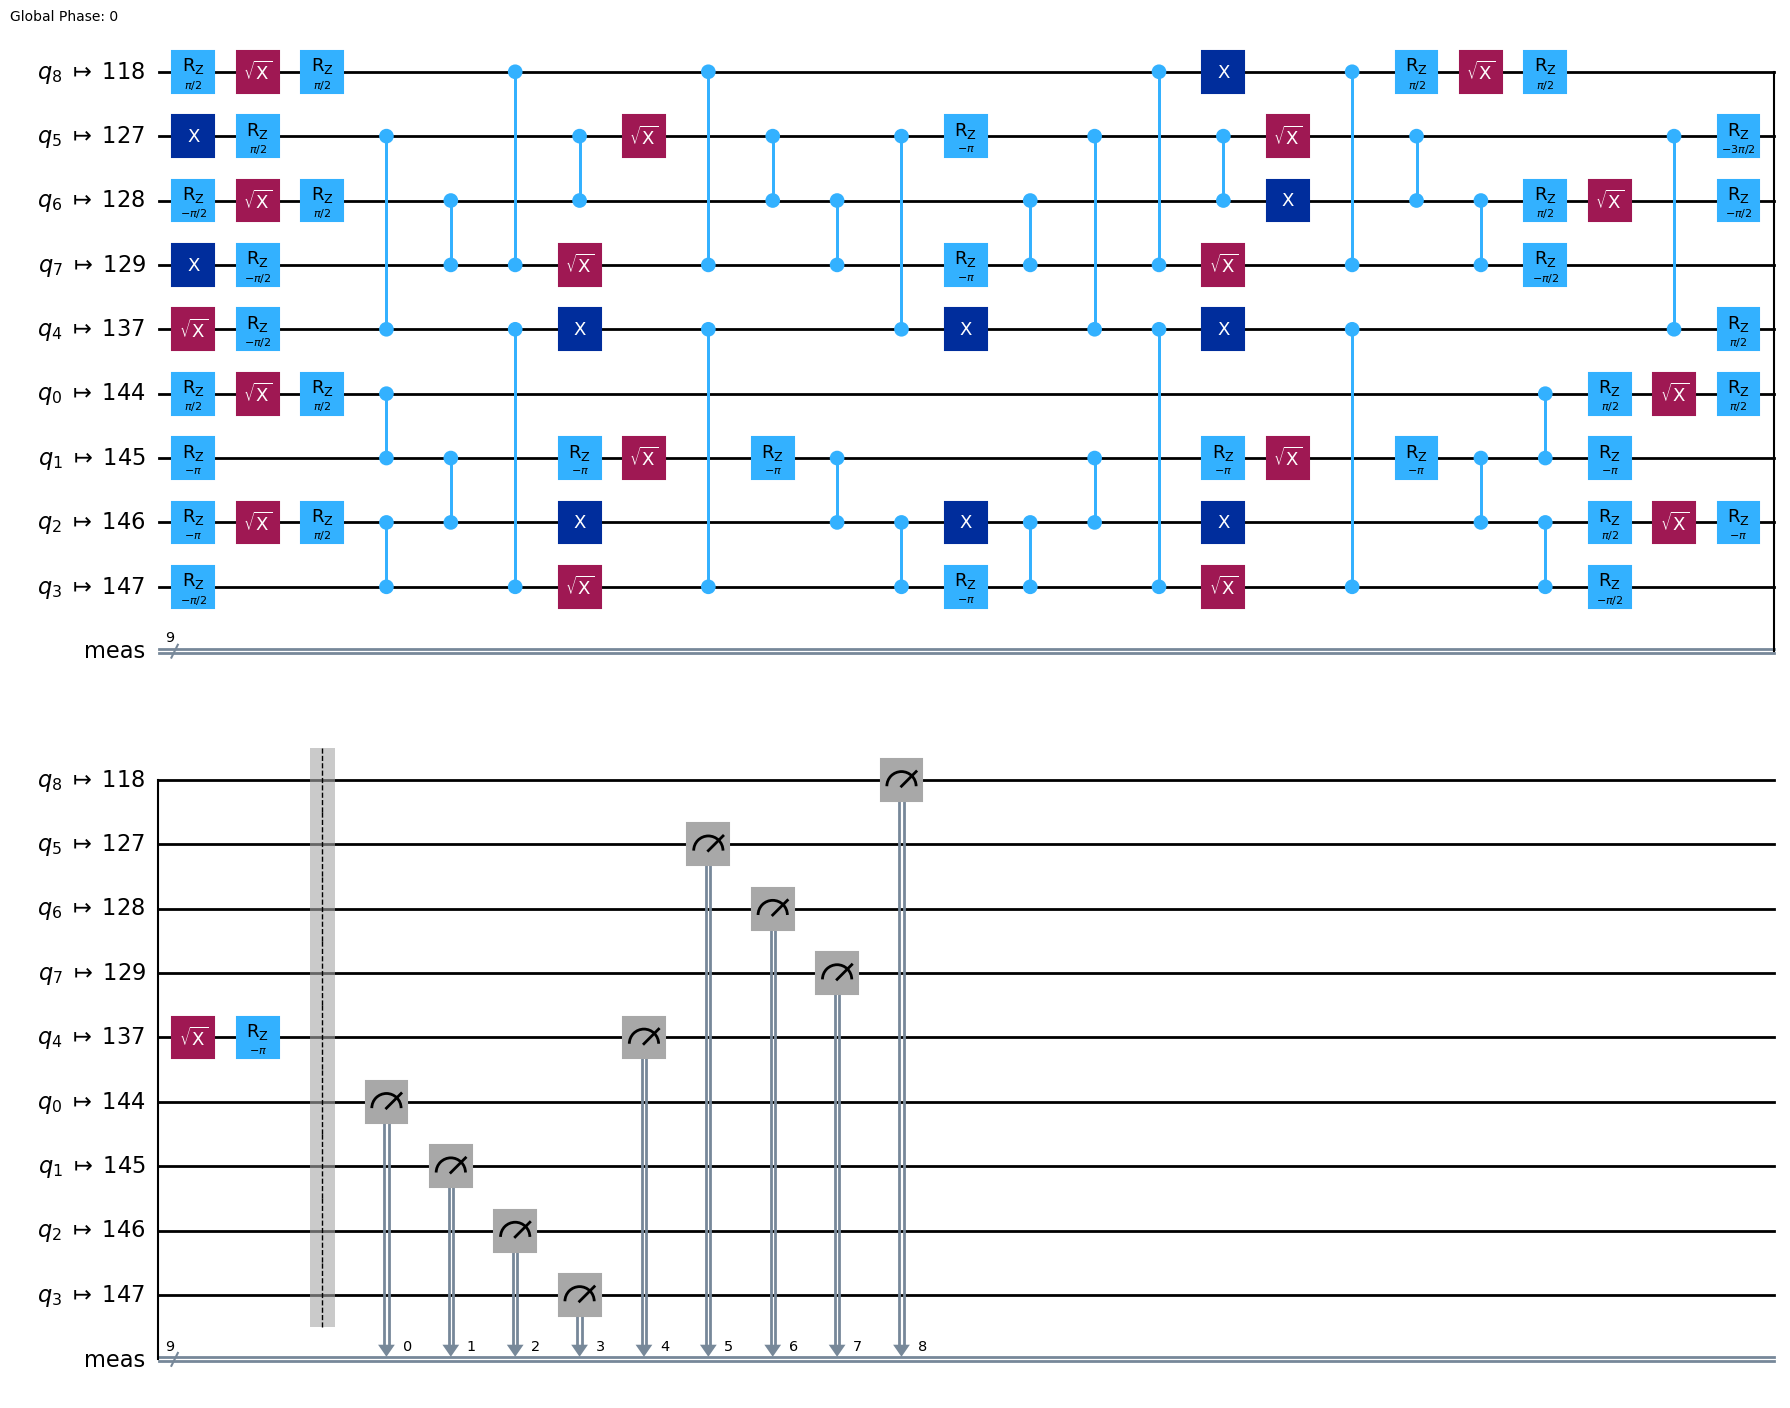

In [27]:
odr_circuits[1].draw(output="mpl", idle_wires=False)

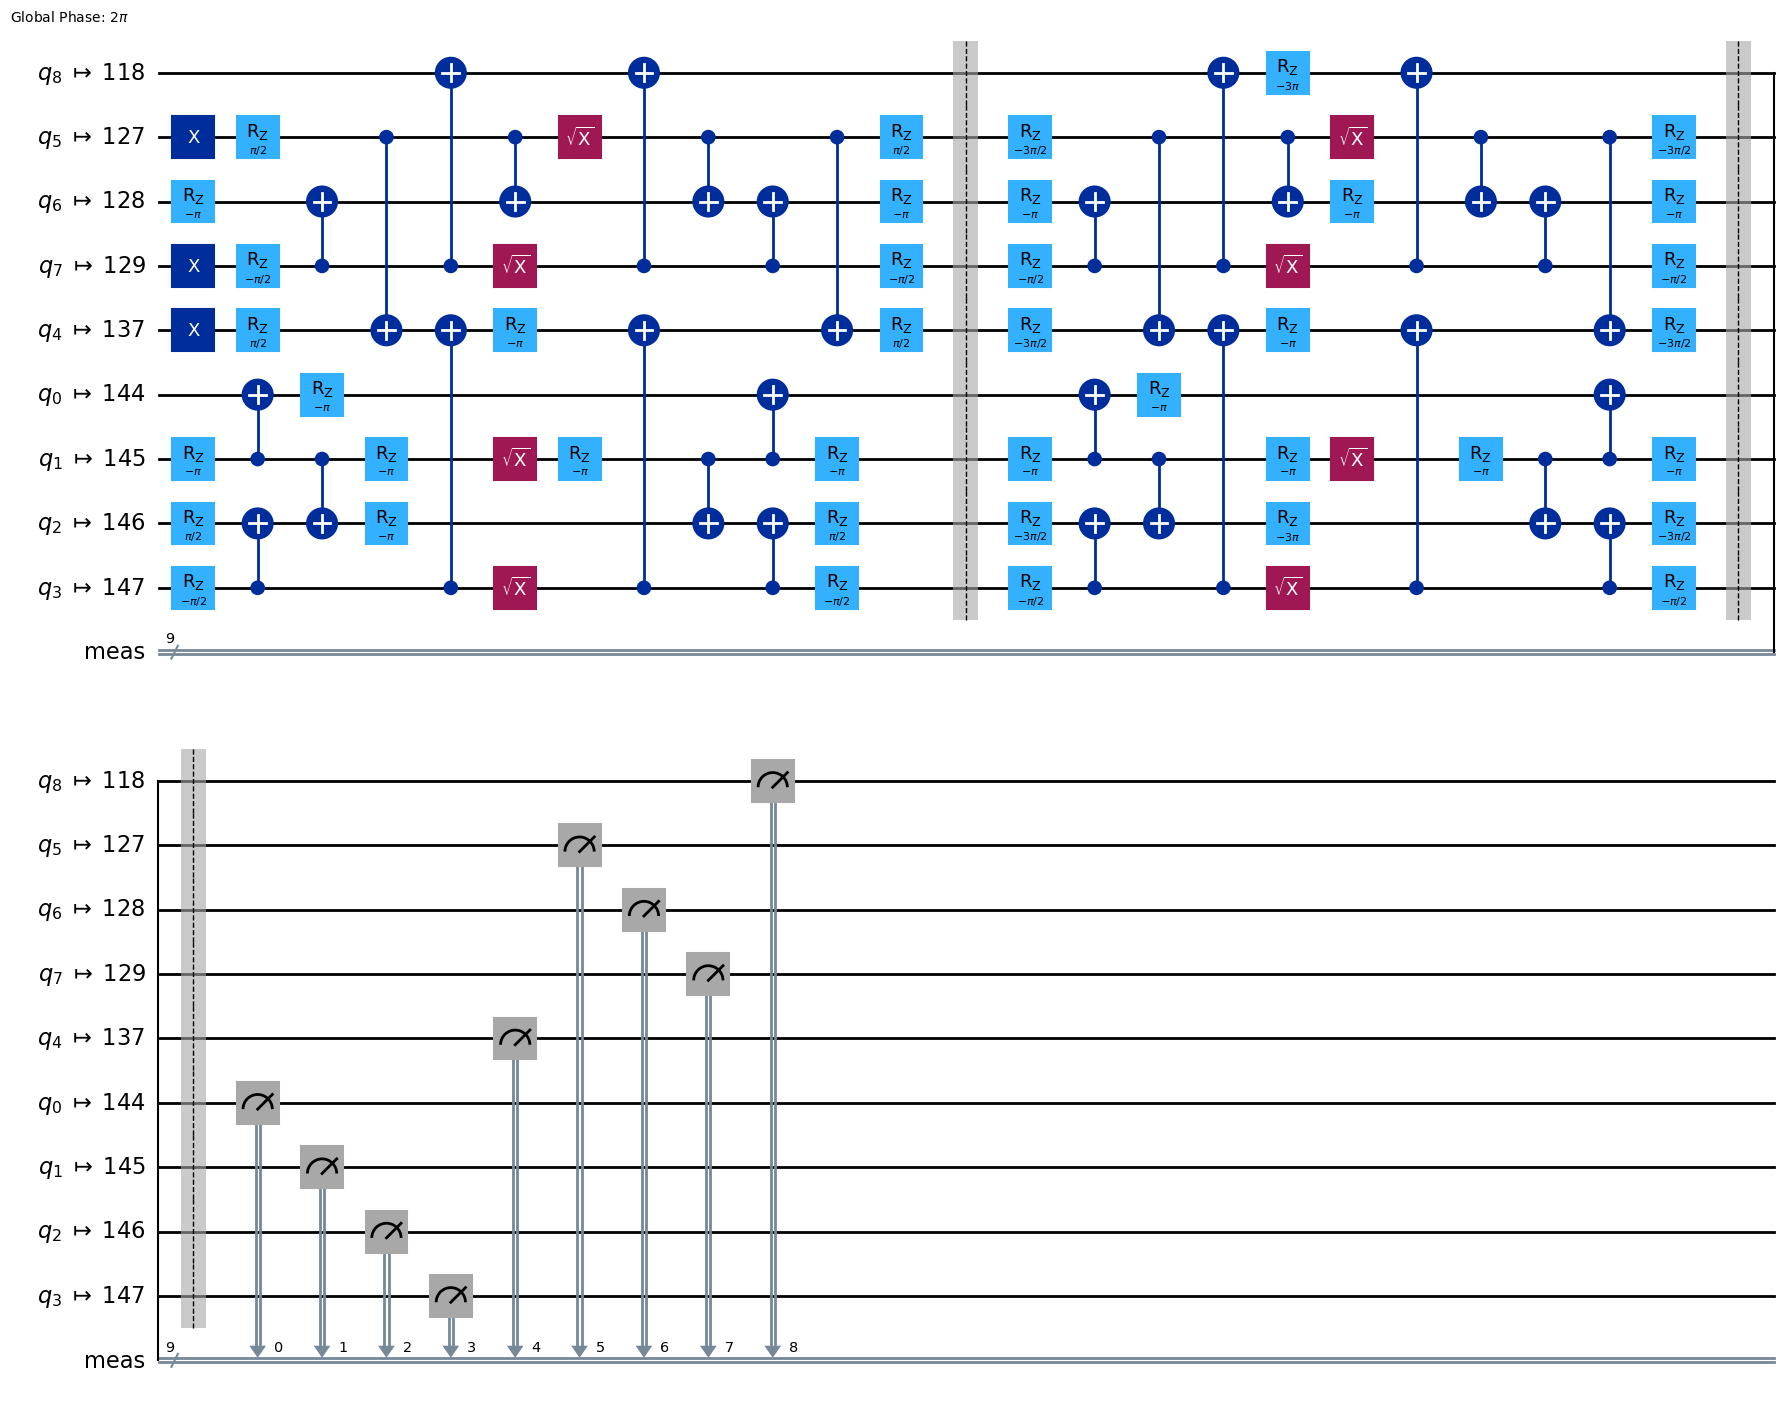

In [28]:
aer_circuits[1].draw(output="mpl", idle_wires=False)

## Simulation

In [29]:
from utils.circs import remove_final_measurements
from qiskit_aer.primitives import SamplerV2
from qiskit_aer import AerSimulator

simulator_options = {
    "backend_options": {"method": "stabilizer"}
}

clifford_simulator = SamplerV2(options=simulator_options)
noisy_simulator = AerSimulator.from_backend(backend)

In [30]:
import numpy as np

samples_dicts = []
odr_samples_dicts = []
ideal_odr_samples_dicts = []
for i in range(len(circuits)):
    print(f"\ri = {i}", end="")
    this_samples_dicts = noisy_simulator.run(circuits[i], shots=shots).result().get_counts()
    this_odr_samples_dicts = noisy_simulator.run(odr_circuits[i], shots=shots).result().get_counts()
    this_ideal_odr_samples_dicts = clifford_simulator.run([aer_circuits[i]], shots=shots).result()[0].data.meas.get_counts()
    samples_dicts.append(this_samples_dicts)
    odr_samples_dicts.append(this_odr_samples_dicts)
    ideal_odr_samples_dicts.append(this_ideal_odr_samples_dicts)
samples_dicts = np.array(samples_dicts, dtype=object)
odr_samples_dicts = np.array(odr_samples_dicts, dtype=object)
ideal_odr_samples_dicts = np.array(ideal_odr_samples_dicts, dtype=object)

i = 40

In [31]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.odr import renormalize_observable, compute_depolarizing_probability
from z2chain.postselection import bias_corrected_get_recovered_samples_dicts

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
if odr:
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(odr_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)

sim_observables, sim_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
raw_observables, raw_observables_confidence = multiprocess_measure_diagonal_observables(samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
odr_observables, odr_observables_confidence = multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
ideal_odr_observables, ideal_odr_observables_confidence = multiprocess_measure_diagonal_observables(ideal_odr_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
clean_observables = np.zeros_like(sim_observables)
clean_observables_confidence = np.zeros_like(sim_observables_confidence)
for i in range(len(sim_observables)):
    p_arr = compute_depolarizing_probability(odr_observables[i], ideal_odr_observables[i], 0, odr_circuits[i].num_qubits)
    clean_observables[i], clean_observables_confidence[i] = renormalize_observable(sim_observables[i], p_arr, 0, circuits[i].num_qubits, observable_range=(-1, 1), expected_observable_arr=ideal_odr_observables[i], observable_confidence=sim_observables_confidence[i])

In [ ]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.odr import renormalize_observable, compute_depolarizing_probability
from z2chain.postselection import bias_corrected_get_recovered_samples_dicts

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
if odr:
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(odr_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)

sim_observables, sim_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
raw_observables, raw_observables_confidence = multiprocess_measure_diagonal_observables(samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
odr_observables, odr_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
# ideal_odr_observables, ideal_odr_observables_confidence = multiprocess_measure_diagonal_observables(ideal_odr_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
ideal_odr_observables = exact_observables
clean_observables = np.zeros_like(sim_observables)
clean_observables_confidence = np.zeros_like(sim_observables_confidence)
for i in range(len(sim_observables)):
    p_arr = compute_depolarizing_probability(odr_observables[i], ideal_odr_observables[i], 0, odr_circuits[i].num_qubits)
    clean_observables[i] = renormalize_observable(sim_observables[i], p_arr, 0, circuits[i].num_qubits, observable_range=(-1, 1), expected_observable_arr=ideal_odr_observables[i])

In [32]:
p_arr = np.zeros_like(sim_observables)
for i in range(len(sim_observables)):
    p_arr[i] = compute_depolarizing_probability(odr_observables[i], ideal_odr_observables[i], 0, odr_circuits[i].num_qubits)

In [33]:
# from z2chain.plotting import x_t_plot

# x_t_plot(p_arr, cbar_range=[0, 1])

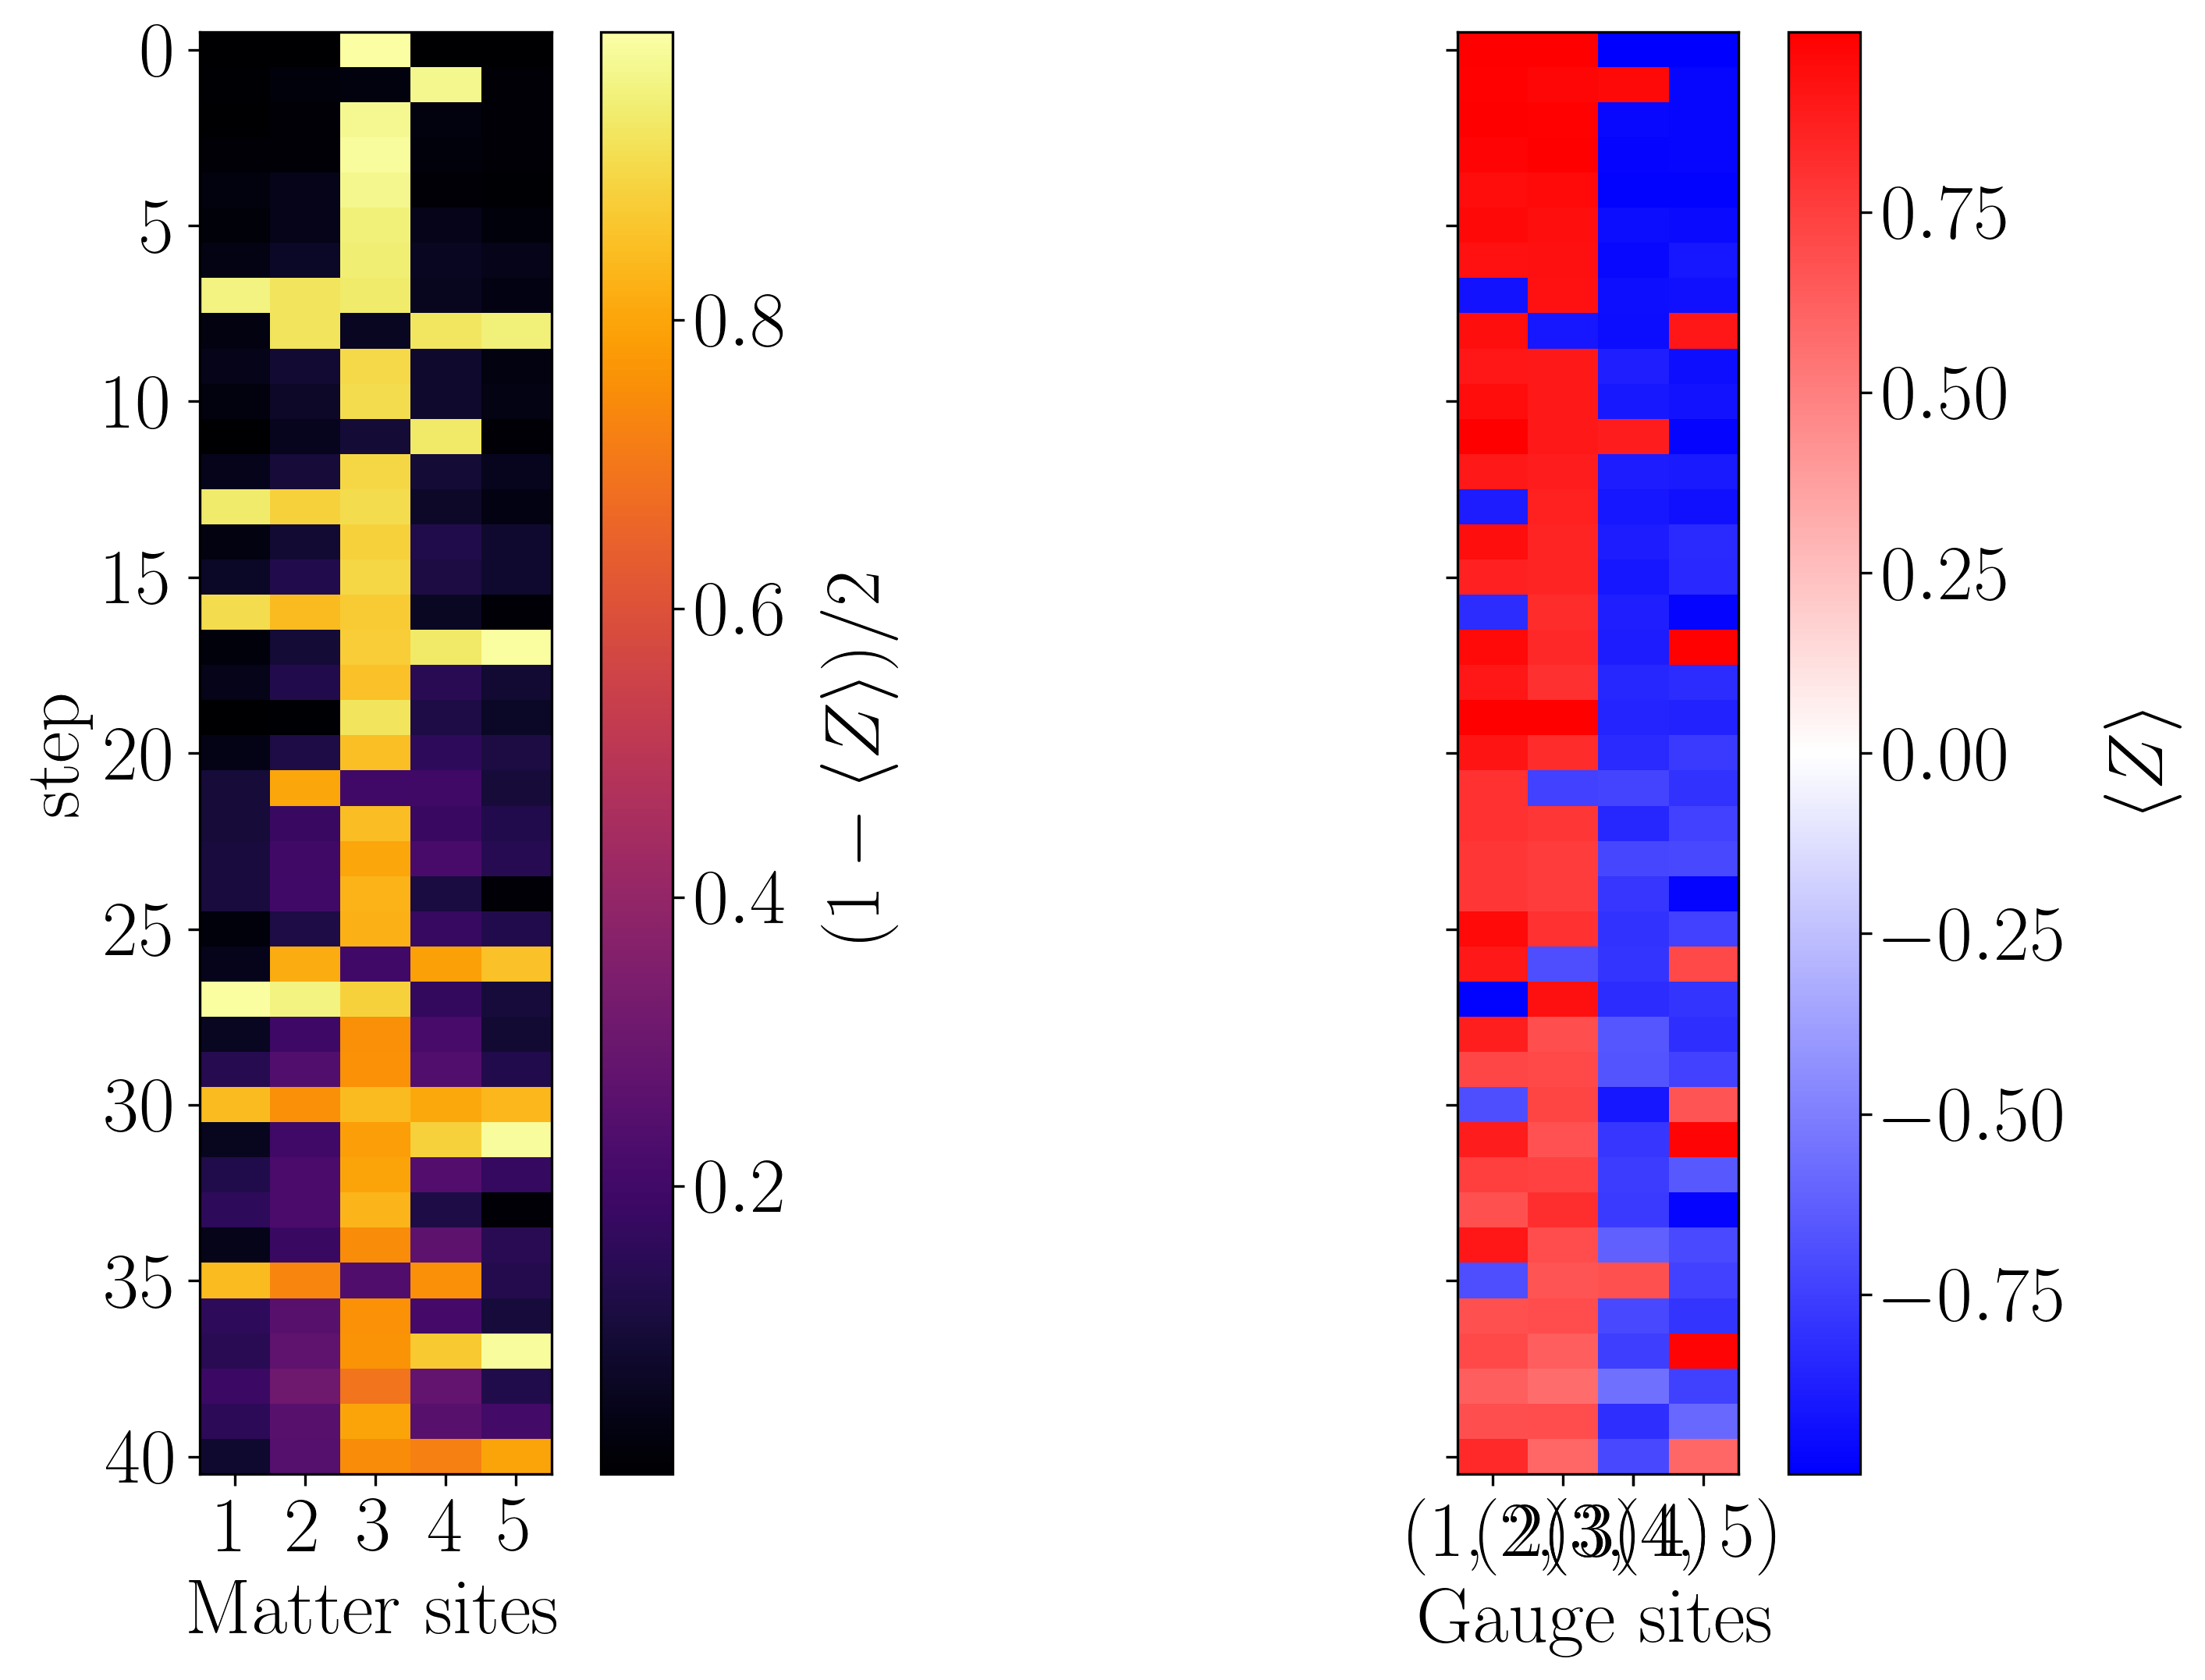

In [34]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(odr_observables)

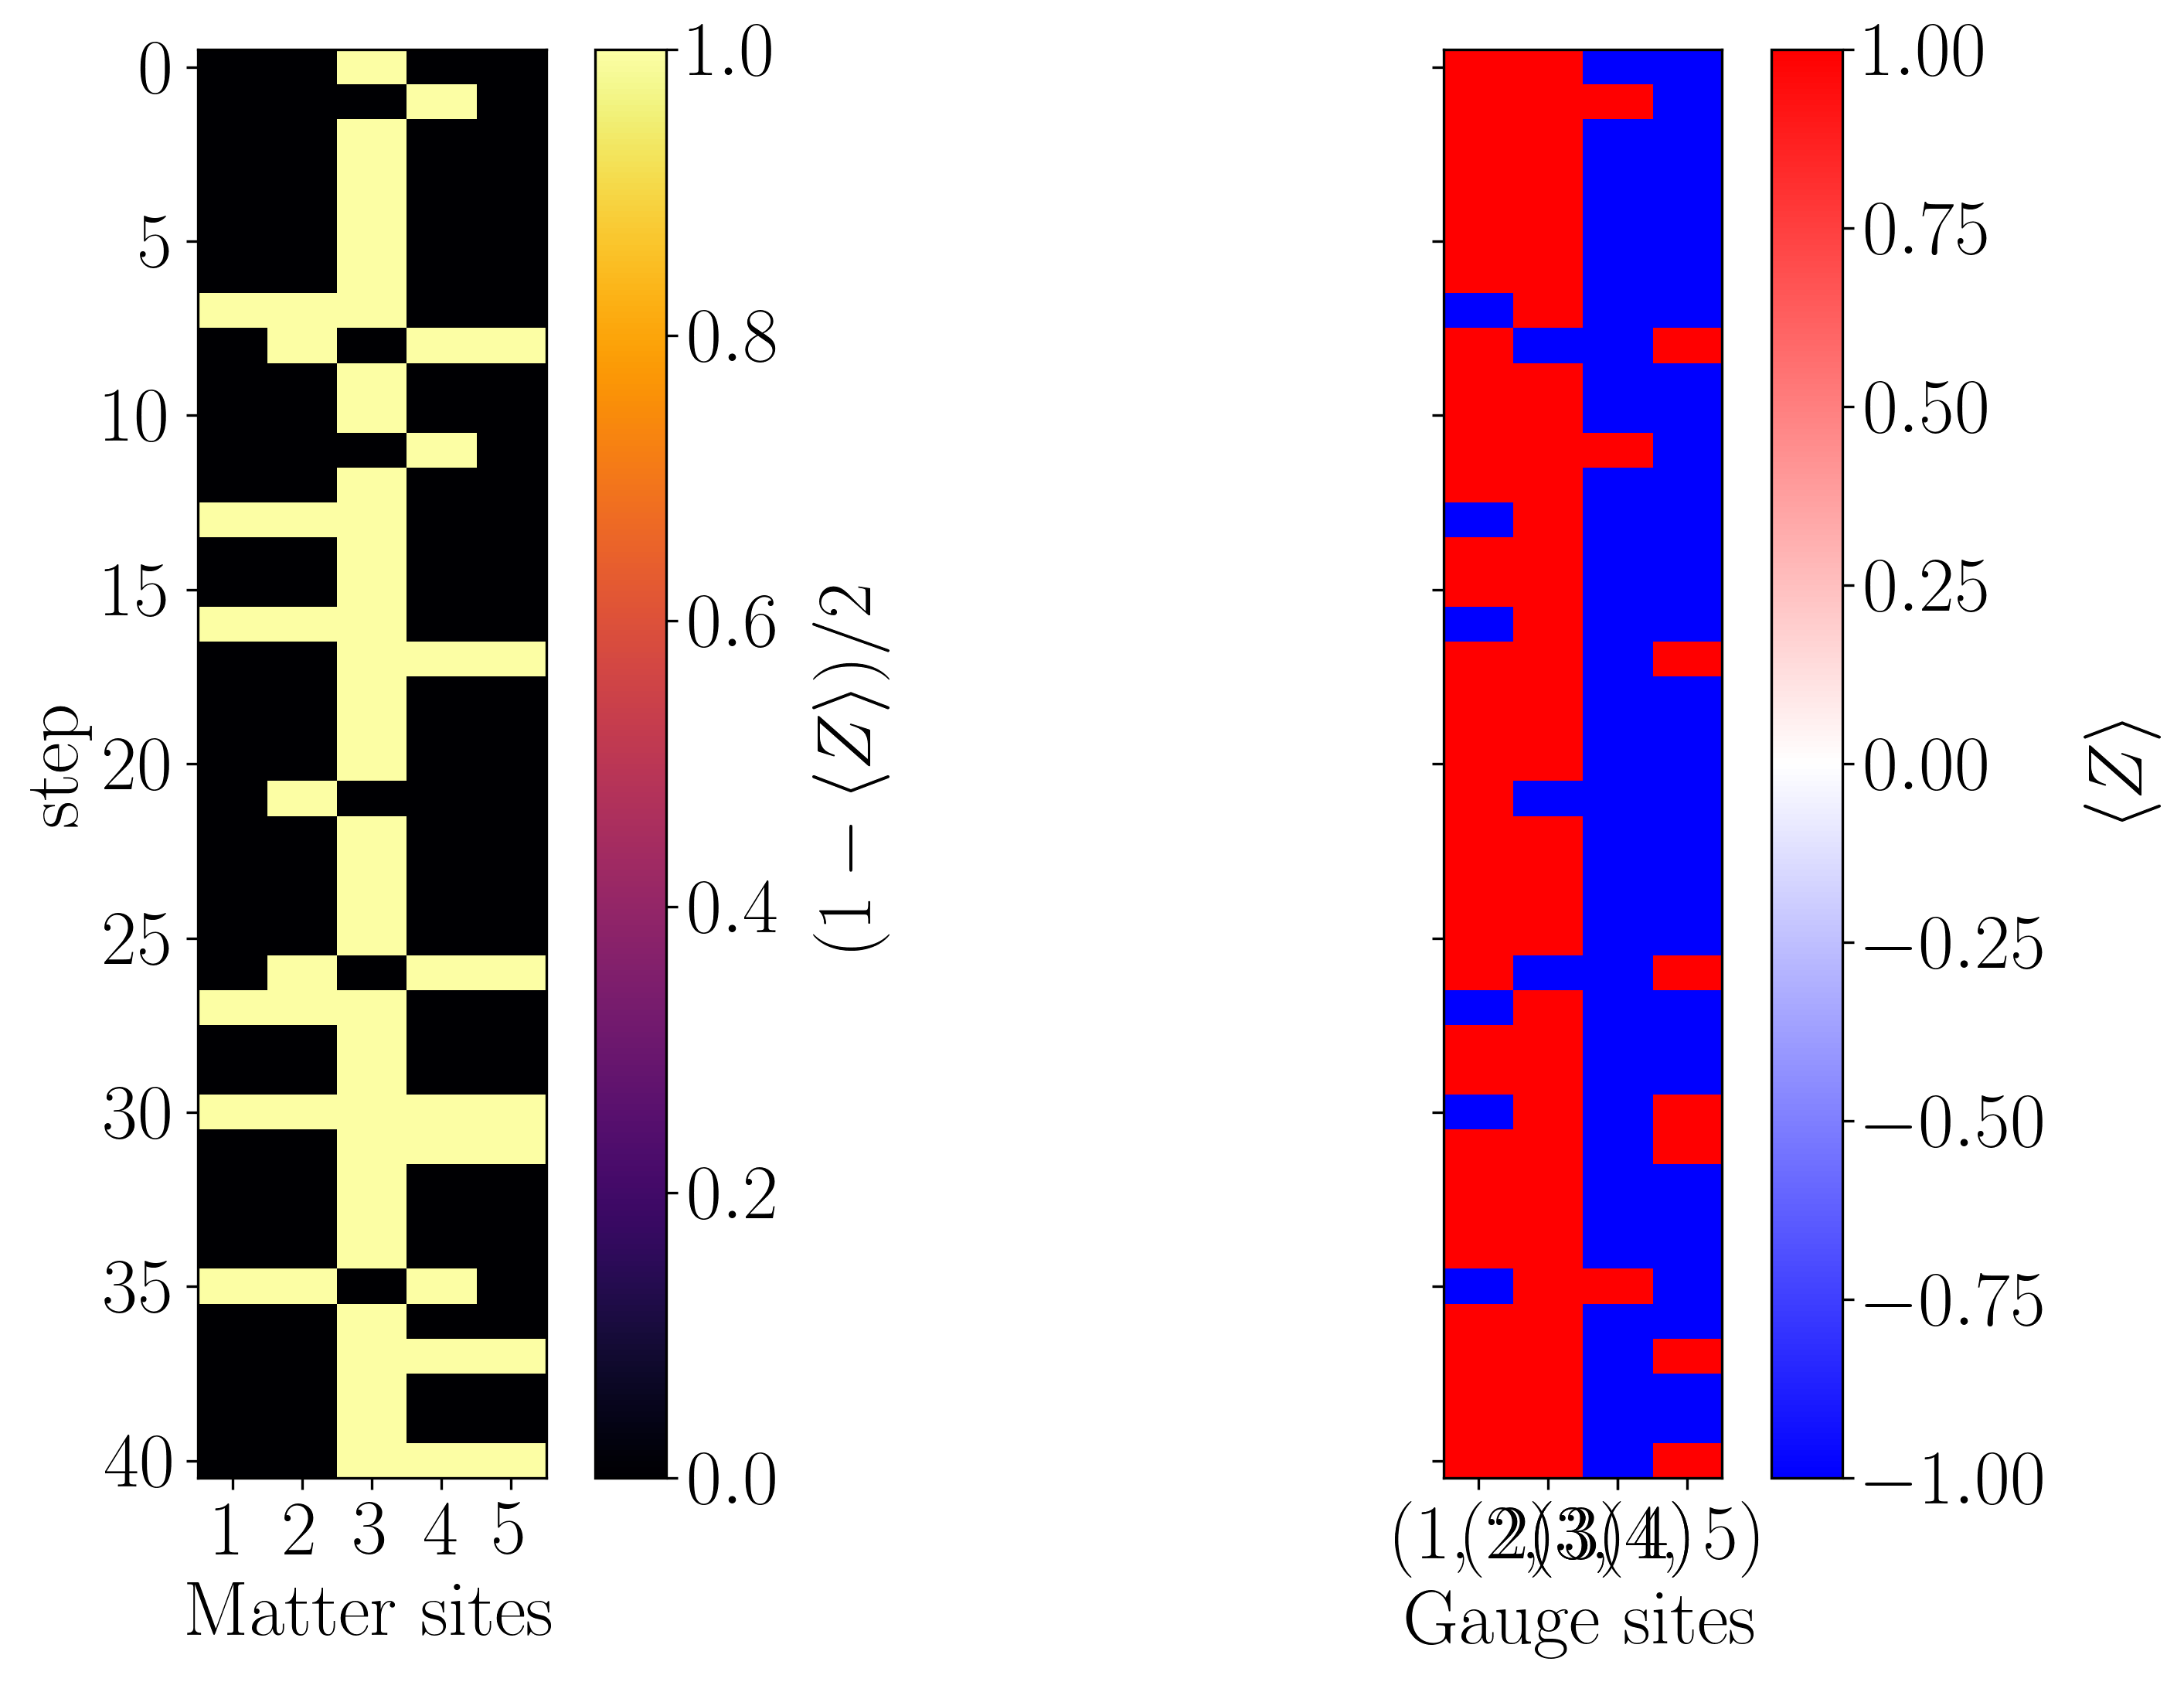

In [35]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(ideal_odr_observables)

In [36]:
ideal_odr_observables[1]

array([ 1.,  1.,  1.,  1.,  1.,  1., -1., -1.,  1.])

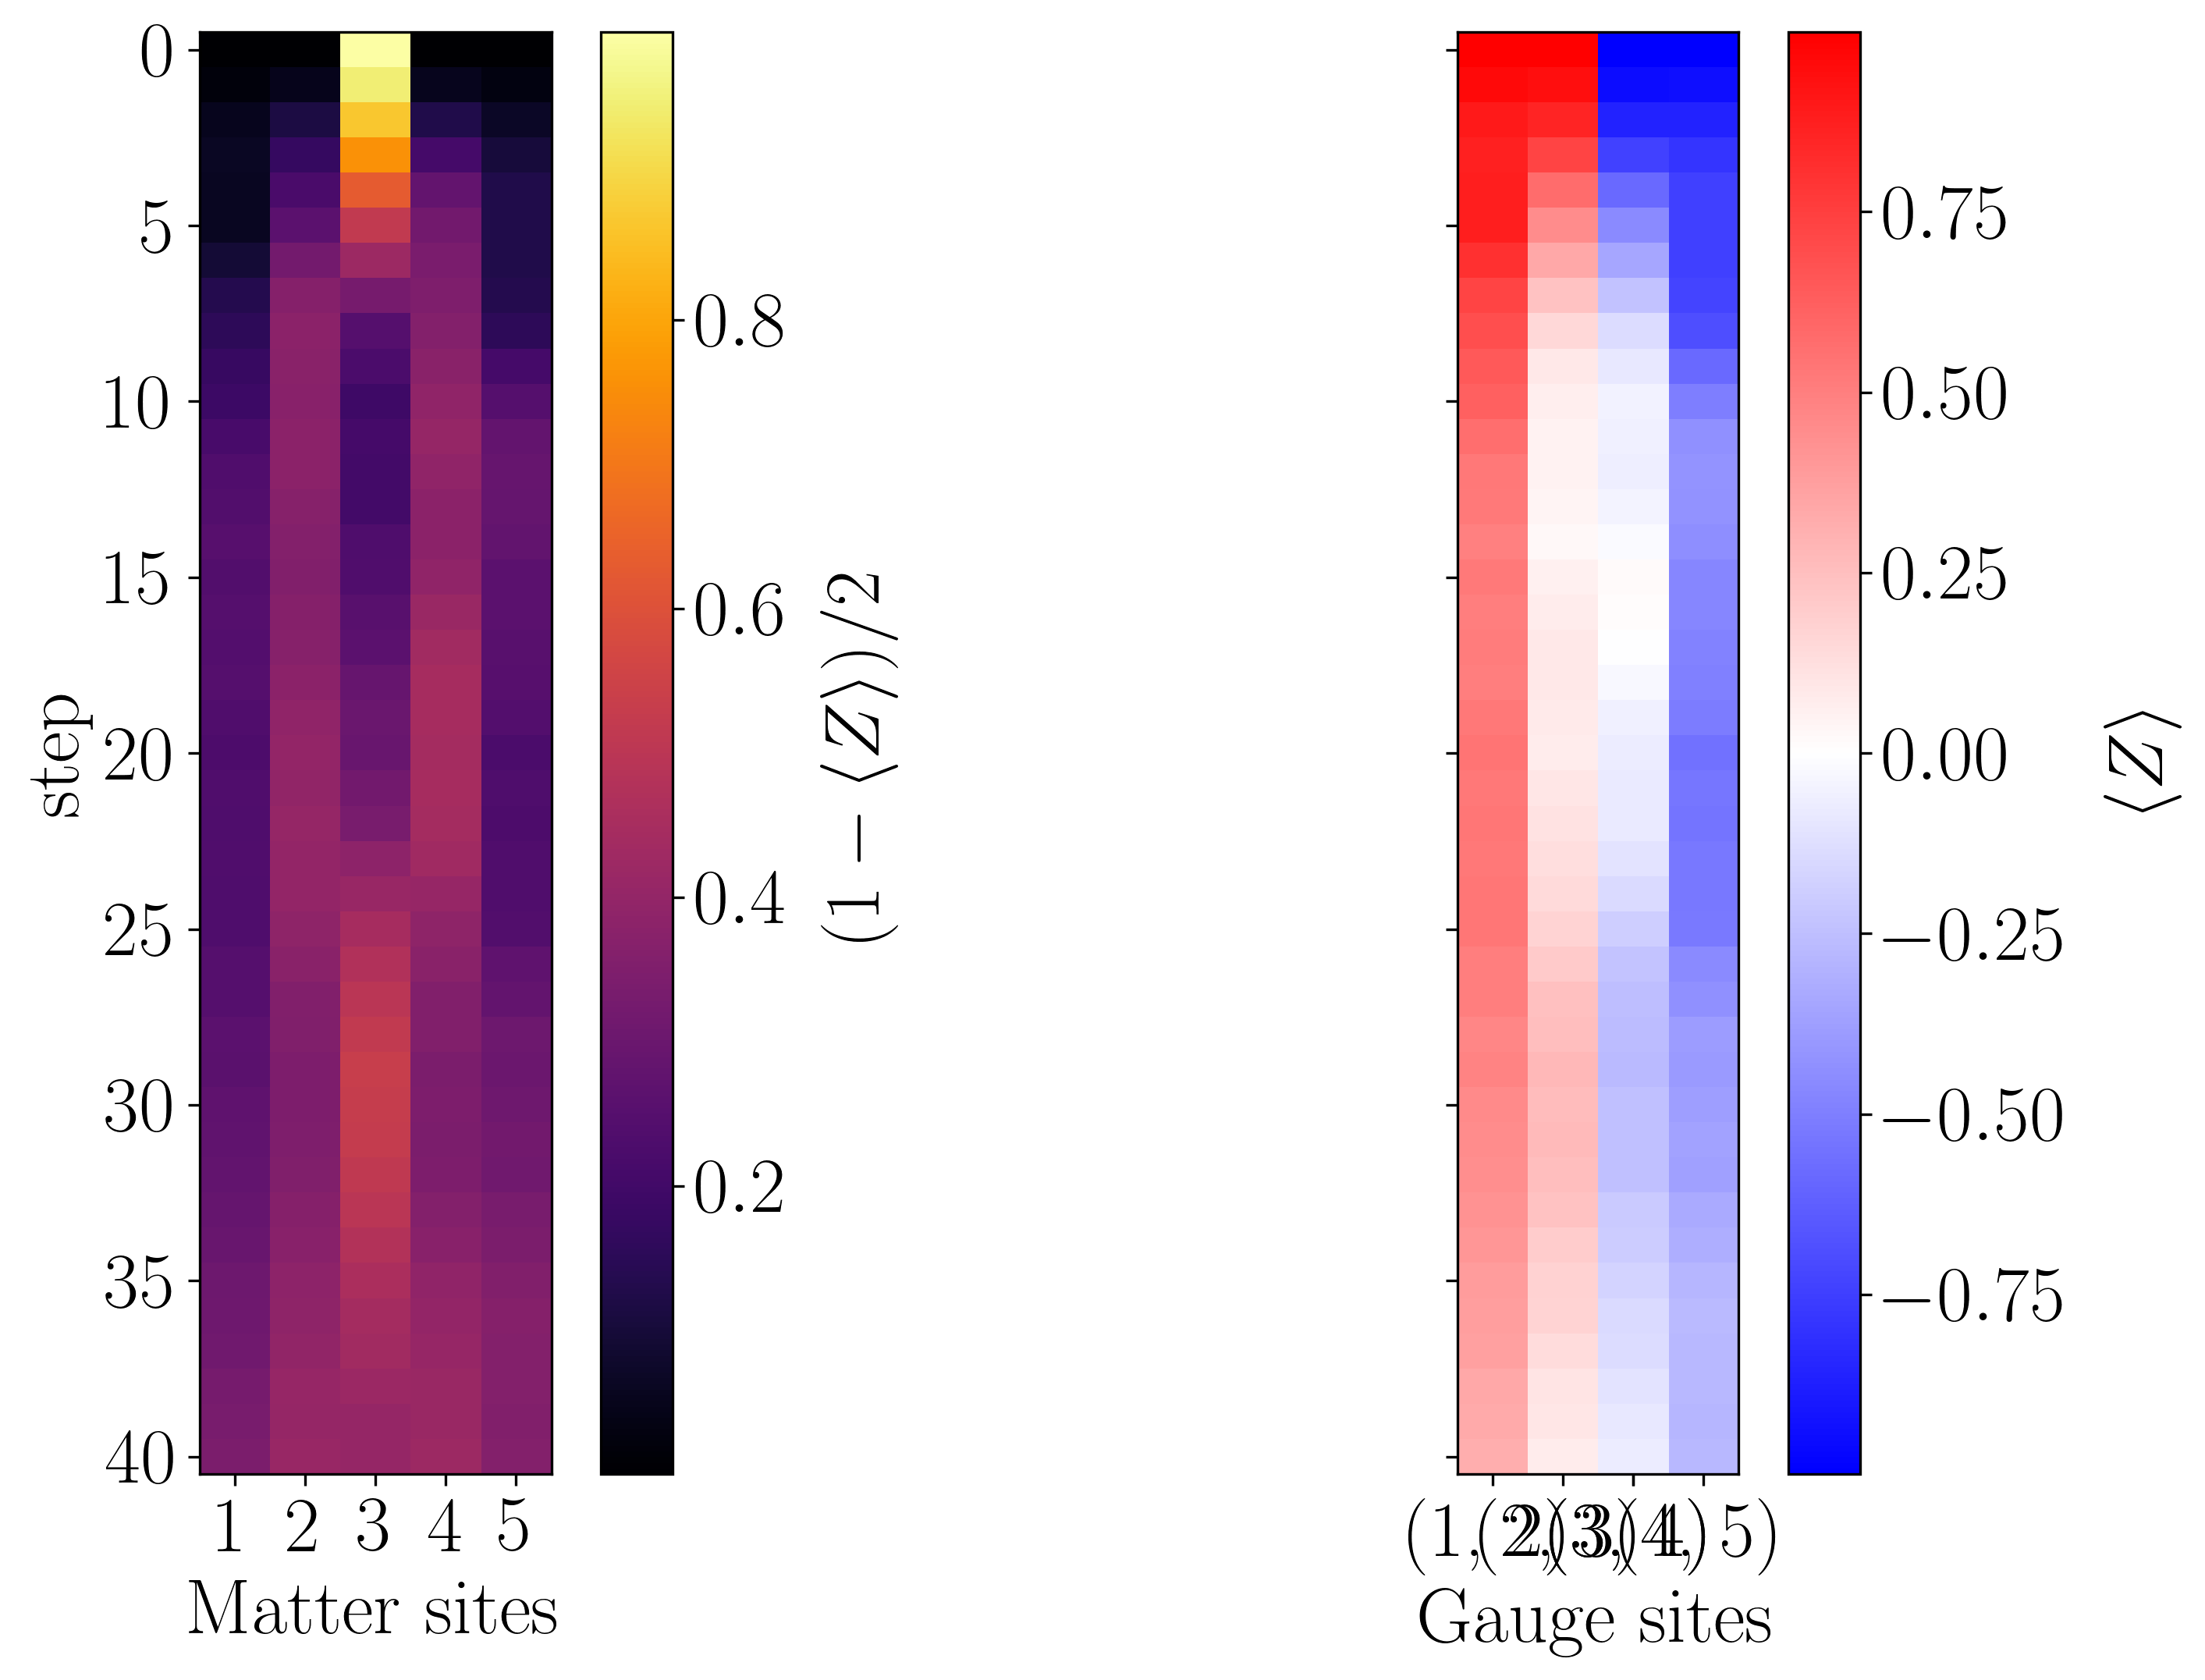

In [37]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(sim_observables)

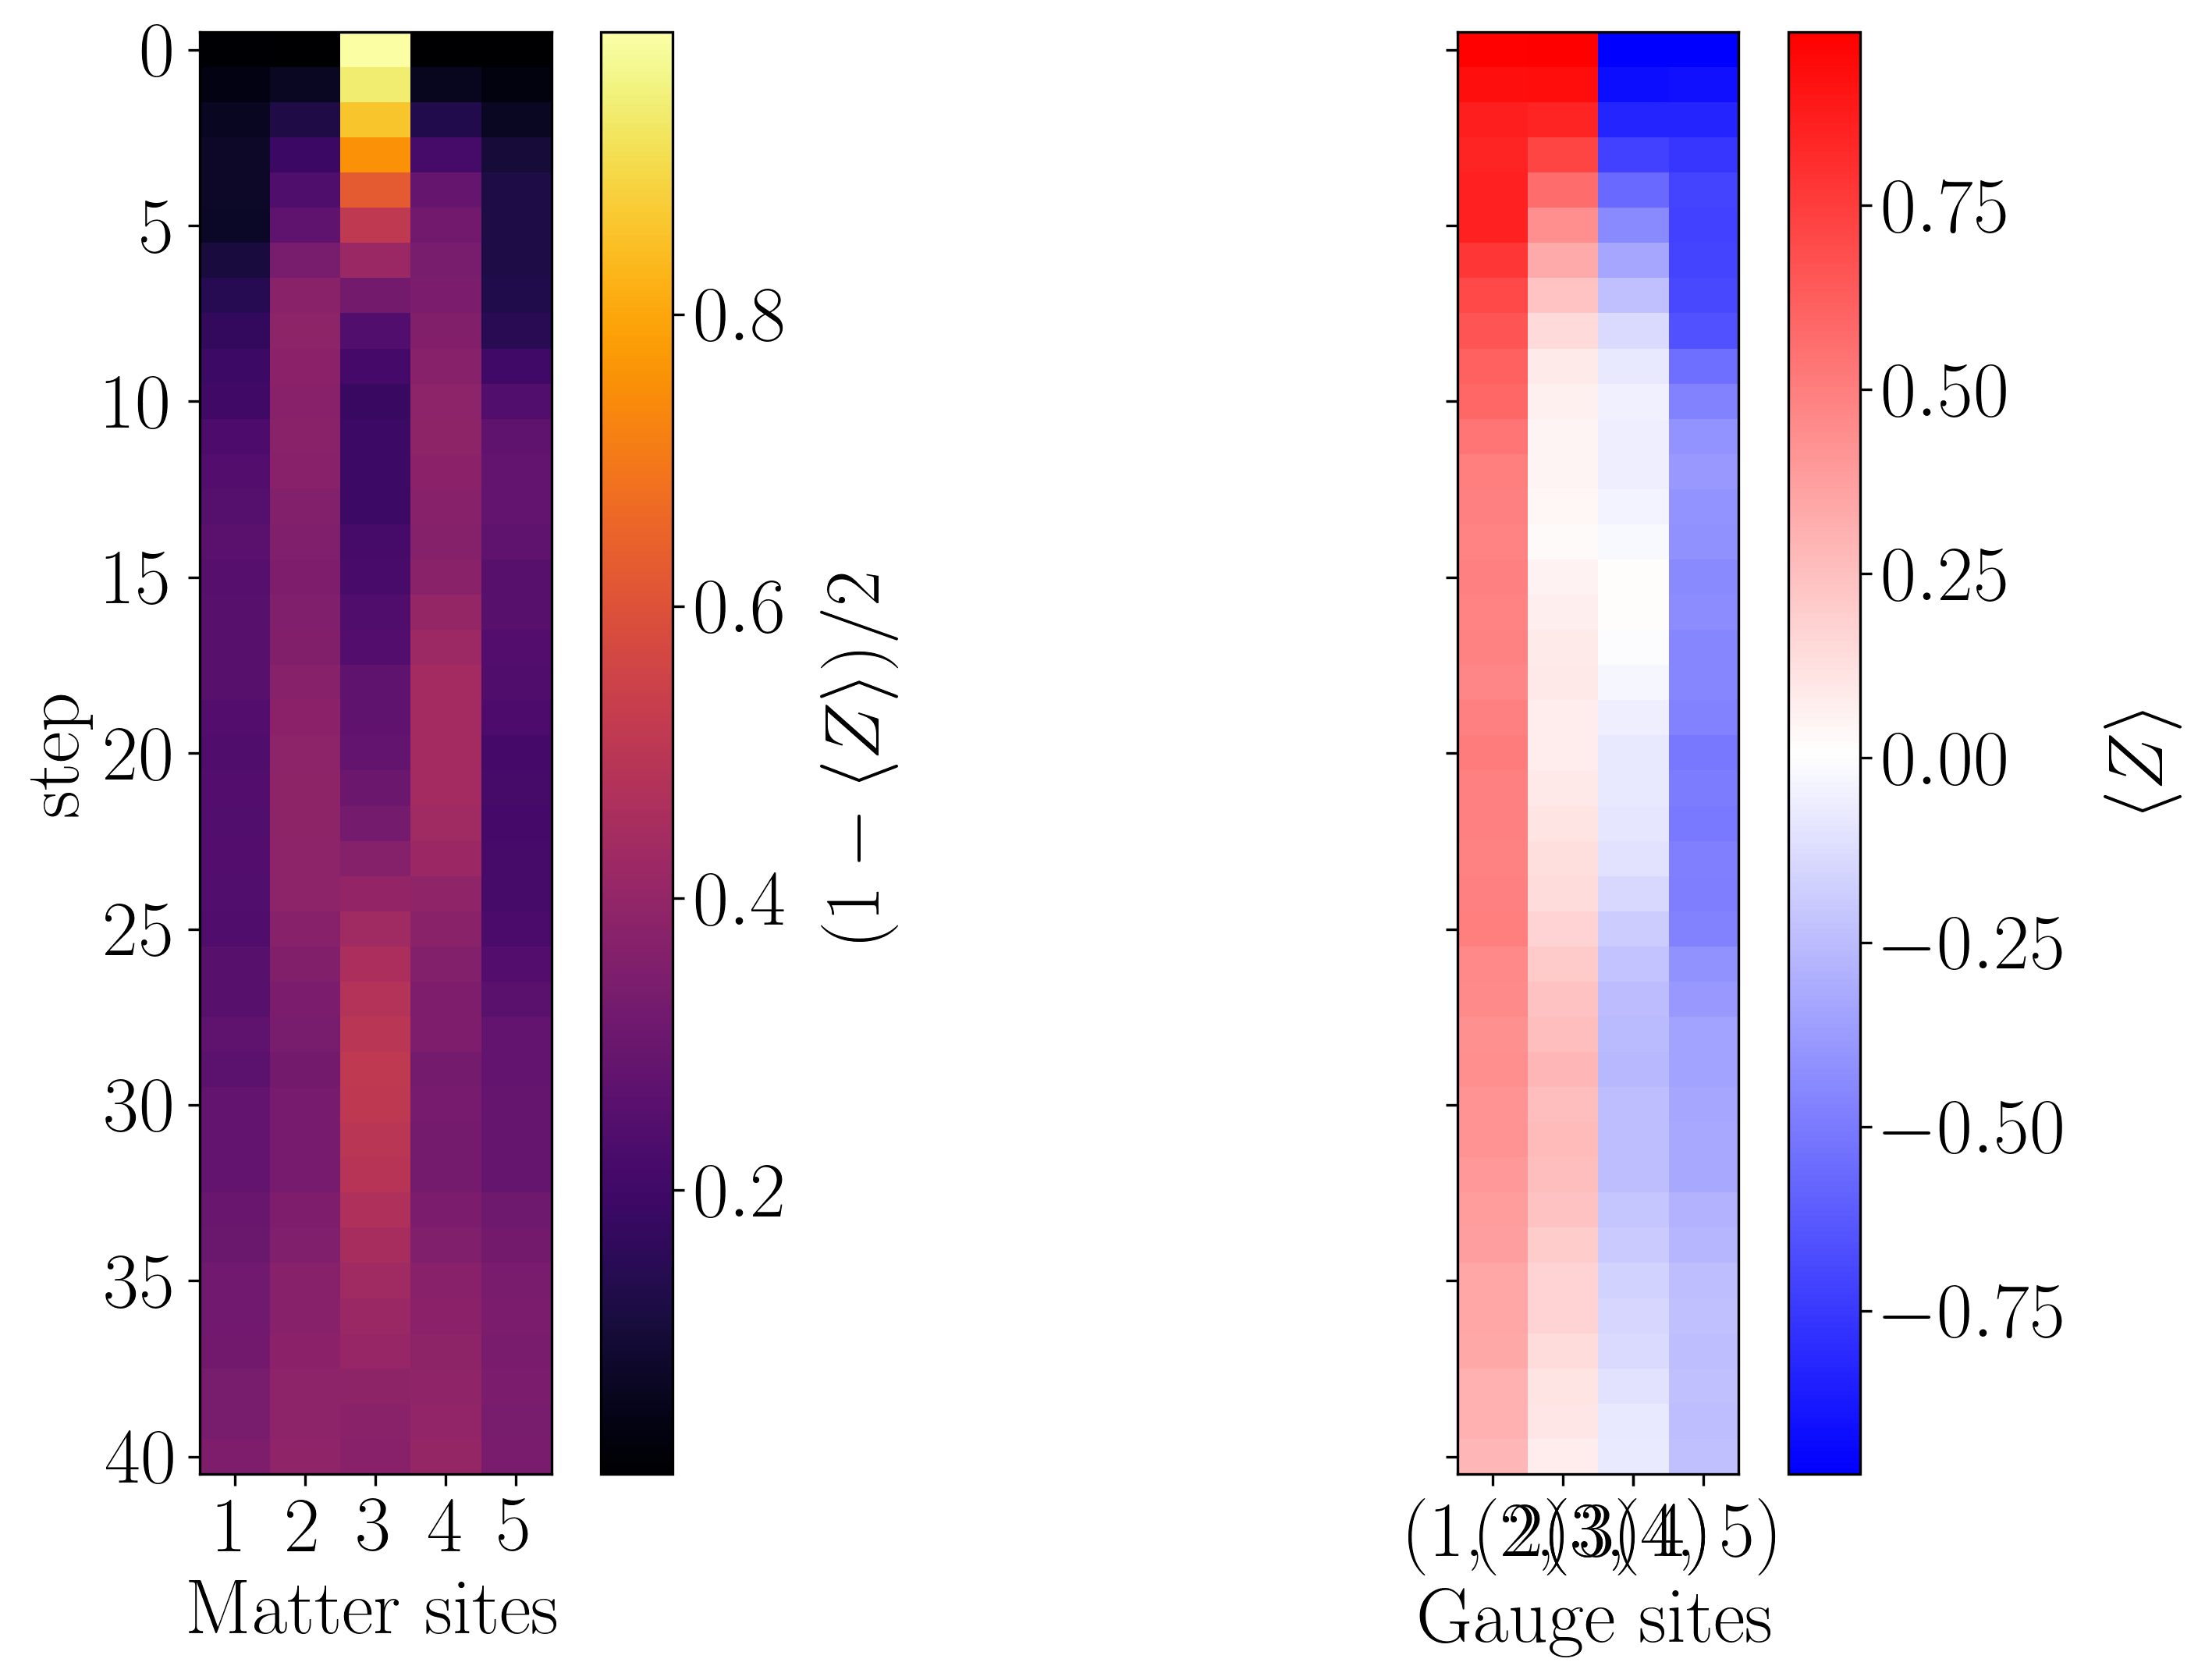

In [38]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(raw_observables)

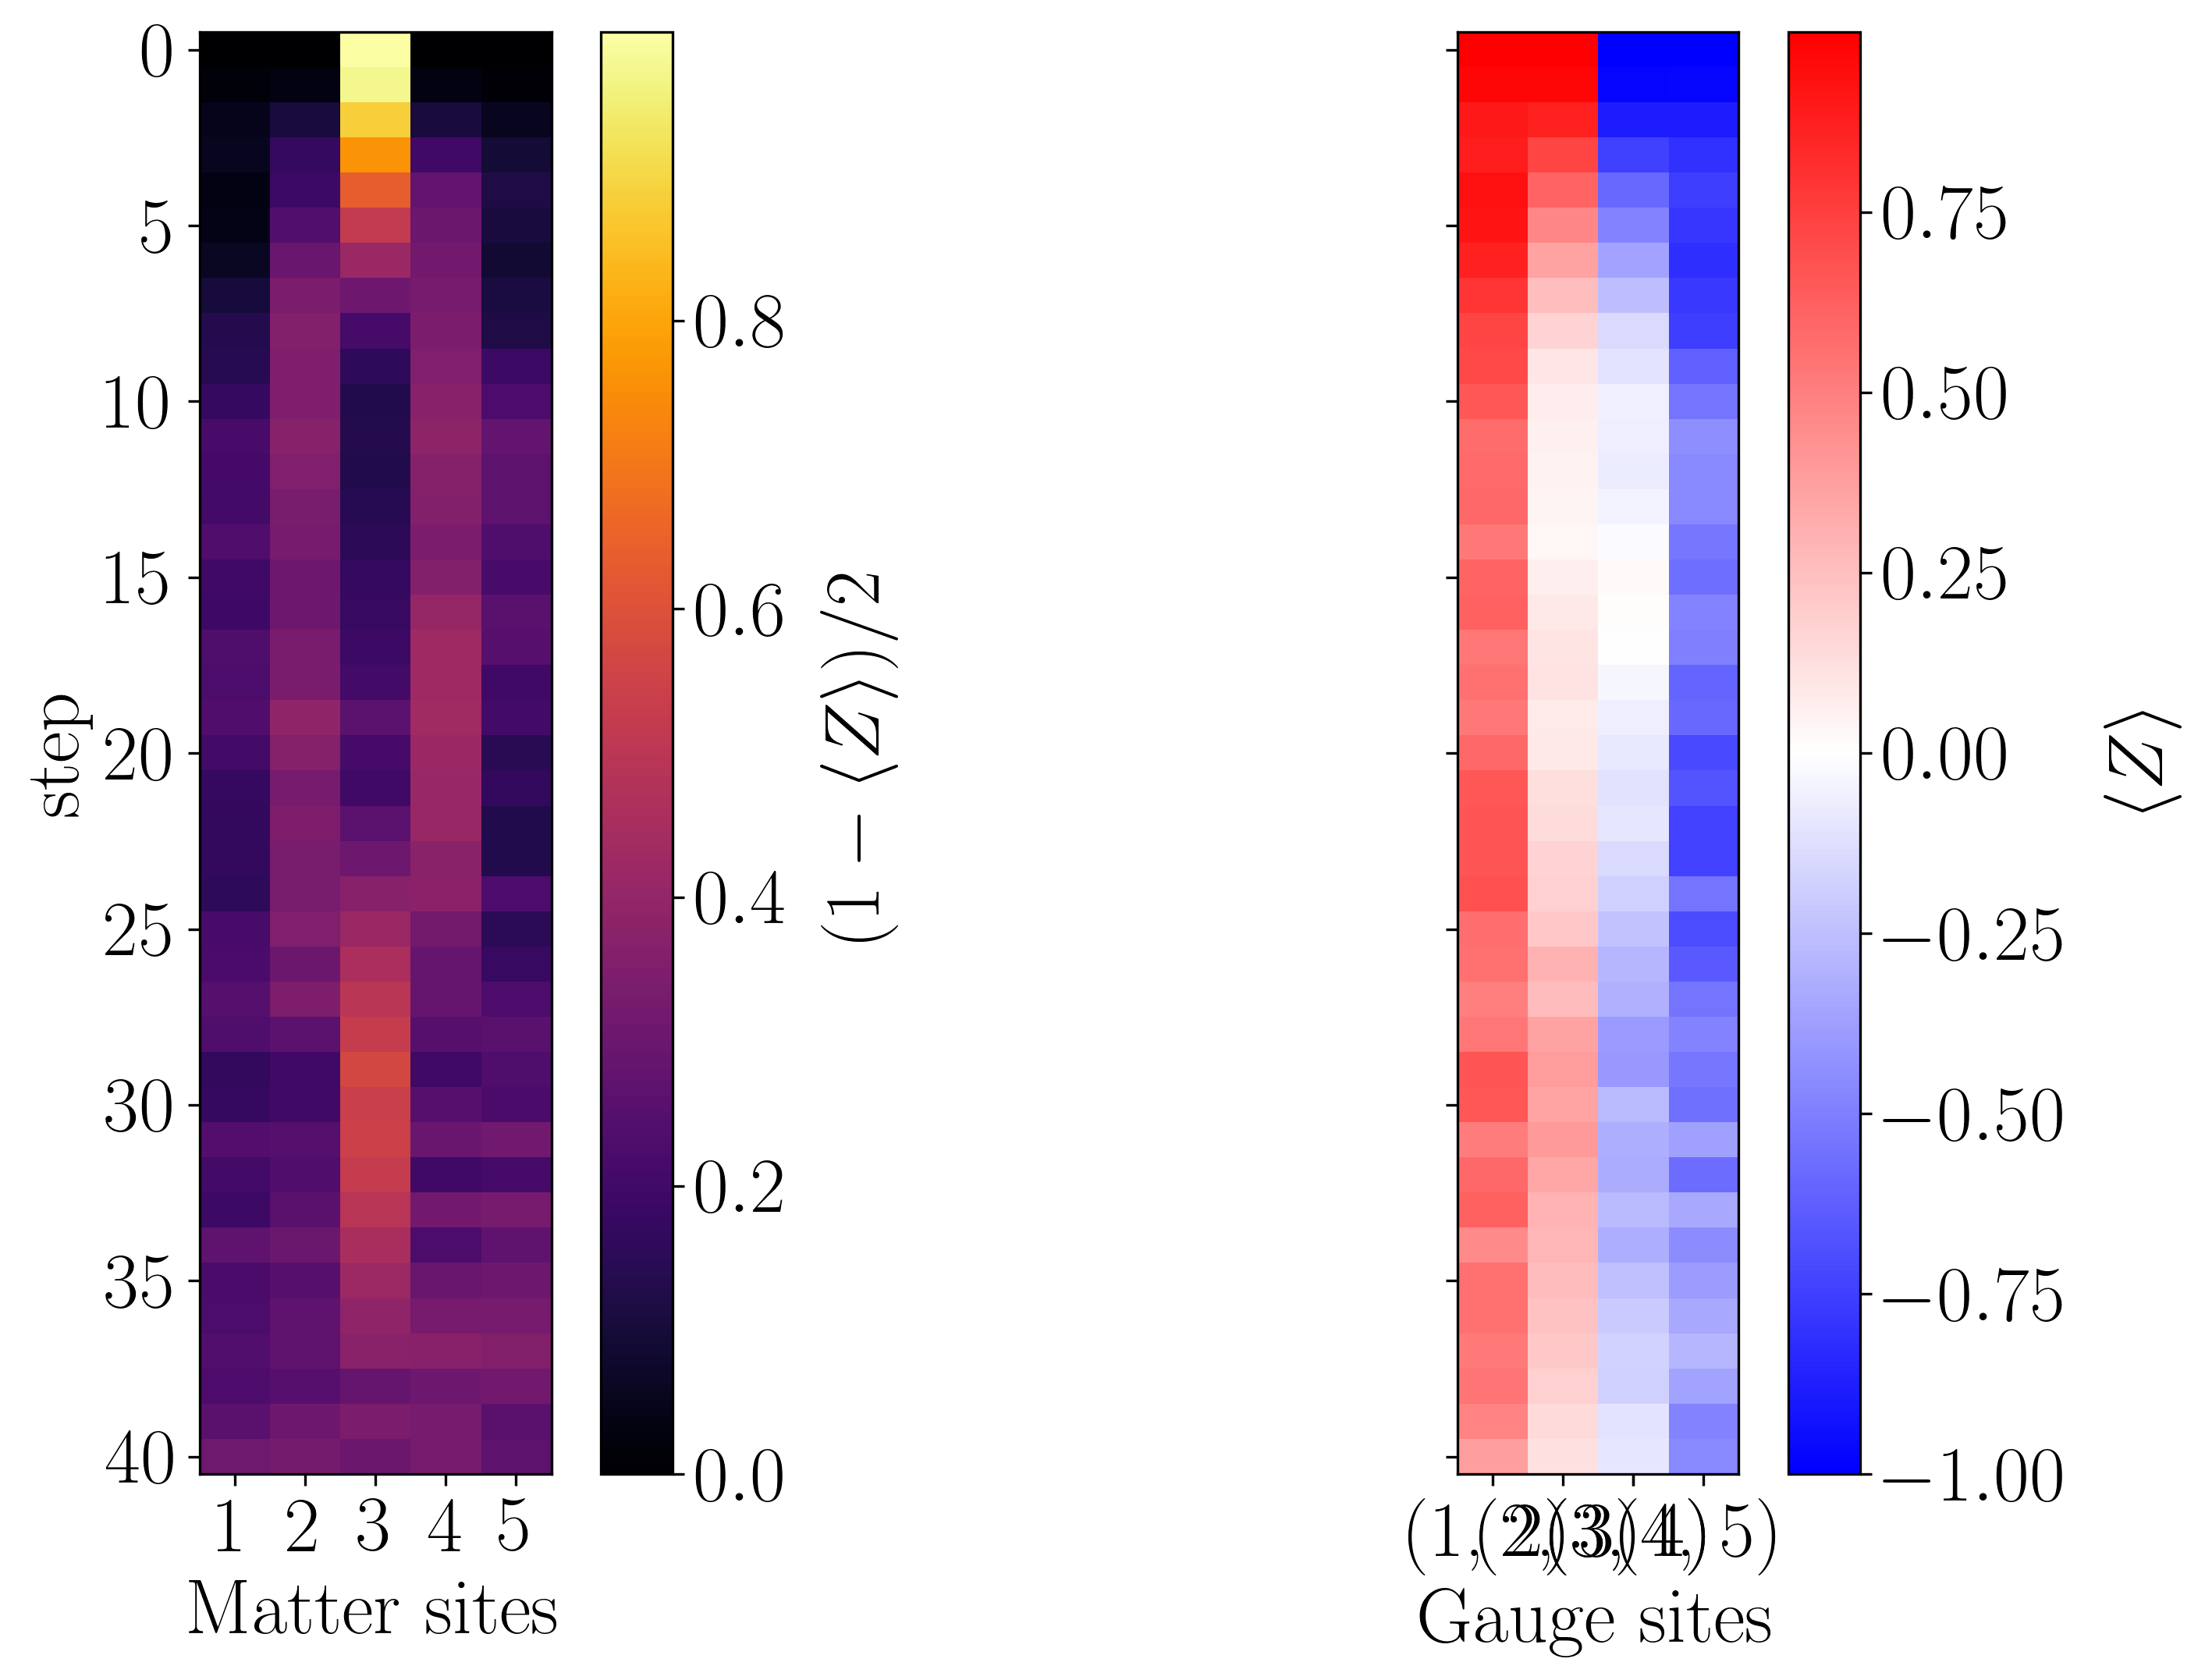

In [39]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_observables)

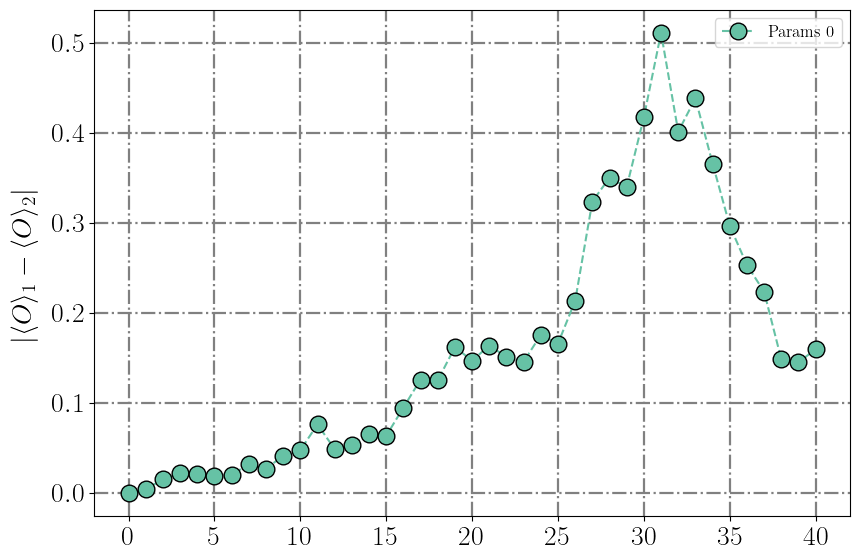

In [40]:
from utils.plotting import plot_mean_deviations

plot_mean_deviations(clean_observables, exact_observables) 